# 02_Cofolded_TAS2R_cryoEM_complexes

In [2]:
import pandas as pd
import numpy as np
import os
from tqdm import tqdm
import yaml

import sys
sys.path.append('../src/TAS2Rs_cofolding_utils/')
from complex_utils import get_ligands_interactions, get_ligands_rmsd
from receptor_region import ReceptorRegionClassyfier
from other import read_json

import seaborn as sns
palette = sns.color_palette('Set1')
custom_palette = {'TAS2R4': palette[4],'TAS2R14': palette[0], 'TAS2R16': palette[1], 'TAS2R43': palette[6], 'TAS2R46': palette[2]}

### Prepare configs for Boltz-2

In [3]:
path_to_meta_file = '../data/TAS2R_cryoEM_compexes/TAS2R_cryoEM_complexes_meta.xlsx'
complexes_meta = pd.read_excel(path_to_meta_file, sheet_name='meta')
ligand_smiles = pd.read_excel(path_to_meta_file, sheet_name='ligands', index_col='ligand')
receptor_sequences = pd.read_excel(path_to_meta_file, sheet_name='receptors', index_col='receptor')

In [3]:
# obtain unique ligand-receptor pairs
ligand_receptor_pairs = []
for _, row in complexes_meta.iterrows():
    ligands = row['ligands']
    receptor = row['receptor']
    for ligand in ligands.split(', '):
        ligand_receptor_pairs.append([ligand, receptor])
ligand_receptor_pairs = pd.DataFrame(ligand_receptor_pairs, columns=['ligand', 'receptor'])
ligand_receptor_pairs.drop_duplicates(ignore_index=True, inplace=True)

In [4]:
directory = 'Cofolded_TAS2R_cryoEM_complexes'
path_to_predictions = os.path.join('../predictions', directory)

path_to_config_directory = os.path.join('../configs/', directory)
if not os.path.exists(path_to_config_directory):
   os.makedirs(path_to_config_directory)

In [5]:
for _, row in ligand_receptor_pairs.iterrows():
    
    ligand = row['ligand']
    
    if ligand == 'apo':
        continue
    
    smiles = ligand_smiles.loc[ligand, 'smiles']
    
    receptor = row['receptor']
    sequence = receptor_sequences.loc[receptor, 'sequence']
    
    # create config
    config_content = {'sequences': [{'protein': {'id': 'R', 'sequence': sequence}}, {'ligand': {'id': 'L', 'smiles': smiles}}],
                      'properties': [{'affinity': {'binder': 'L'}}]}

    # save config
    config_name = f'{ligand}-{receptor}.yaml'
    path_to_config = os.path.join(path_to_config_directory, config_name)
    with open(path_to_config, 'w') as out:
      yaml.safe_dump(config_content, out, sort_keys=False, allow_unicode=True)

### Run Boltz-2

In [6]:
# !boltz predict $path_to_config_directory --out_dir $path_to_predictions --diffusion_samples 5 --output_format pdb --use_msa_server

### Load cryo-EM complexes

In [5]:
# load ReceptorRegionClassyfier
path_to_msa = '../data/sequences/TAS2Rs T-Coffee aligned.fa'
path_to_regions = '../data/sequences/TAS2Rs_known_regions.xlsx'
region_classyfier = ReceptorRegionClassyfier(path_to_regions, path_to_msa)

In [3]:
# Load metadata on TAS2R cryo-EM complexes
path_to_meta_file = '../data/TAS2R_cryoEM_compexes/TAS2R_cryoEM_complexes_meta.xlsx'
TAS2R_cryoEM_complexes_meta = pd.read_excel(path_to_meta_file)
# Obtain the PDB codes for the published TAS2R cryo-EM complexes
published_TAS2R_cryoEM_pdb_codes = set(TAS2R_cryoEM_complexes_meta['PDB code'].dropna())

In [4]:
# Load TAS2R cryo-EM complexes with one ligand per complex
TAS2R_cryoEM_complexes = []
path_to_TAS2R_cryoEM_complexes_dir = '../data/TAS2R_cryoEM_compexes/one_ligand_per_complex/'
pdb_files = [file for file in os.listdir(path_to_TAS2R_cryoEM_complexes_dir) if file.endswith('.pdb')]

for pdb_file in pdb_files:

    ligand, receptor, Galpha, pdb_code = pdb_file.rstrip('.pdb').split('-')
    ligand = ligand.replace('_', ' ')
    if '(' in ligand:
        ligand = ligand[:-3]

    if not pdb_code in published_TAS2R_cryoEM_pdb_codes:
        continue

    path_to_file = os.path.join(path_to_TAS2R_cryoEM_complexes_dir, pdb_file)

    interactions = get_ligands_interactions(path_to_file)
    interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(f'h{receptor}', residue))
    binding_site = interactions['Region'].value_counts().idxmax()

    TAS2R_cryoEM_complexes.append([path_to_file, pdb_file, ligand, receptor, Galpha, pdb_code, interactions, binding_site])

TAS2R_cryoEM_complexes_df = pd.DataFrame(TAS2R_cryoEM_complexes, columns=['path to file', 'file name', 'ligand', 'receptor', 'Gα', 'PDB code', 'interactions', 'binding site'])
print(f'Number of cryo-EM complexes: {len(TAS2R_cryoEM_complexes_df['PDB code'].unique())}')

Number of cryo-EM complexes: 27


In [5]:
files_to_drop = ['aristolochic_acid(2)-TAS2R14-miniGgust-8XQL.pdb', 'aristolochic_acid-TAS2R14-Ggust-8XQP.pdb', 'cholesterol(2)-TAS2R14-Gi1-8XQT.pdb']
TAS2R_cryoEM_complexes_df = TAS2R_cryoEM_complexes_df[~TAS2R_cryoEM_complexes_df['file name'].isin(files_to_drop)].reset_index(drop=True)

### Load co-folding results

In [6]:
cofolding_results = []
path_to_cofolding_results = '../predictions/Cofolded_TAS2R_cryoEM_complexes/'

for directory in os.listdir(path_to_cofolding_results):

    ligand, receptor = directory.split('-')
    path_to_directory = os.path.join(path_to_cofolding_results, directory)
    pdb_files = [file for file in os.listdir(path_to_directory) if file.endswith('.pdb')]

    for pdb_file in sorted(pdb_files):

        path_to_file = os.path.join(path_to_directory, pdb_file)
        interactions = get_ligands_interactions(path_to_file)
        interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(f'h{receptor}', residue))
        binding_site = interactions['Region'].value_counts().idxmax()

        confidence_file = f"confidence_{pdb_file.replace('.pdb', '.json')}"
        path_to_confidence_file = os.path.join(path_to_directory, confidence_file)
        confidence_data = read_json(path_to_confidence_file)
        cofolding_results.append([path_to_file, pdb_file, ligand, receptor, interactions, binding_site, confidence_data])

cofolding_results_df = pd.DataFrame(cofolding_results, columns=['path to file', 'file name', 'ligand', 'receptor', 'interactions', 'binding site', 'confidence data'])
cofolding_results_df['iptm'] = cofolding_results_df['confidence data'].apply(lambda confidence_data: confidence_data['iptm'])

In [10]:
df = cofolding_results_df.copy()
df['complex'] = df['ligand'] + ' - ' + df['receptor']

grouped = df.groupby('complex')['iptm']
mean = grouped.mean().to_frame('mean')
std = grouped.std().to_frame('std')

summary = mean.join(std).round(2).reset_index()
summary[['ligand', 'receptor']] = summary['complex'].str.split(' - ', expand=True)
receptors_order = ['TAS2R4', 'TAS2R14', 'TAS2R16', 'TAS2R43', 'TAS2R46']
summary['receptor'] = pd.Categorical(summary['receptor'], categories=receptors_order, ordered=True)
ligands_order = ['WWW', 'cholesterol', 'tangeretin', 'chlorhexidine', 'compound 28.1', 'flufenamic acid', 'aristolochic acid', 'cholesteryl hemisuccinate', 'diiodosalicylic acid', 'salicin', 'strychnine', 'denatonium', 'artemisinin']
summary['ligand'] = pd.Categorical(summary['ligand'], categories=ligands_order, ordered=True)
summary.sort_values(by=['receptor', 'ligand'], inplace=True, ignore_index=True)
summary['iptm'] = summary['mean'].astype('str') + ' ± ' + summary['std'].astype('str')

summary[['ligand', 'receptor', 'iptm']]

,ligand,receptor,iptm
0,WWW,TAS2R4,0.93 ± 0.01
1,cholesterol,TAS2R14,0.78 ± 0.09
2,tangeretin,TAS2R14,0.86 ± 0.06
3,chlorhexidine,TAS2R14,0.86 ± 0.03
4,compound 28.1,TAS2R14,0.92 ± 0.01
5,flufenamic acid,TAS2R14,0.89 ± 0.03
6,aristolochic acid,TAS2R14,0.88 ± 0.03
7,cholesteryl hemisuccinate,TAS2R14,0.69 ± 0.05
8,diiodosalicylic acid,TAS2R14,0.93 ± 0.01
9,salicin,TAS2R16,0.96 ± 0.0


In [24]:
cofolding_results_df.groupby(by=['ligand', 'receptor'])['iptm'].mean()

ligand                     receptor
WWW                        TAS2R4      0.925088
aristolochic acid          TAS2R14     0.875031
                           TAS2R43     0.880616
artemisinin                TAS2R46     0.873982
chlorhexidine              TAS2R14     0.855043
cholesterol                TAS2R14     0.777717
cholesteryl hemisuccinate  TAS2R14     0.687021
compound 28.1              TAS2R14     0.918055
denatonium                 TAS2R46     0.908474
diiodosalicylic acid       TAS2R14     0.926875
flufenamic acid            TAS2R14     0.892967
salicin                    TAS2R16     0.962241
strychnine                 TAS2R46     0.961820
tangeretin                 TAS2R14     0.858353
                           TAS2R46     0.865383
Name: iptm, dtype: float64

In [25]:
cofolding_results_df[cofolding_results_df['iptm'] < 0.75]

,path to file,file name,ligand,receptor,interactions,binding site,confidence data,iptm
6,../predictions/Cofolded_TAS2R_cryoEM_complexes...,cholesteryl hemisuccinate-TAS2R14_model_1.pdb,cholesteryl hemisuccinate,TAS2R14,Interaction Type Residue Amino Acid ...,extracellular,"{'confidence_score': 0.7480429410934448, 'ptm'...",0.712914
7,../predictions/Cofolded_TAS2R_cryoEM_complexes...,cholesteryl hemisuccinate-TAS2R14_model_2.pdb,cholesteryl hemisuccinate,TAS2R14,Interaction Type Residue Amino Acid ...,intracellular,"{'confidence_score': 0.7374672889709473, 'ptm'...",0.695905
8,../predictions/Cofolded_TAS2R_cryoEM_complexes...,cholesteryl hemisuccinate-TAS2R14_model_3.pdb,cholesteryl hemisuccinate,TAS2R14,Interaction Type Residue Amino Acid ...,intracellular,"{'confidence_score': 0.7291210293769836, 'ptm'...",0.612964
9,../predictions/Cofolded_TAS2R_cryoEM_complexes...,cholesteryl hemisuccinate-TAS2R14_model_4.pdb,cholesteryl hemisuccinate,TAS2R14,Interaction Type Residue Amino Acid ...,intracellular,"{'confidence_score': 0.7253530025482178, 'ptm'...",0.658592
67,../predictions/Cofolded_TAS2R_cryoEM_complexes...,cholesterol-TAS2R14_model_2.pdb,cholesterol,TAS2R14,Interaction Type Residue Amino Acid ...,intracellular,"{'confidence_score': 0.761443555355072, 'ptm':...",0.746780
68,../predictions/Cofolded_TAS2R_cryoEM_complexes...,cholesterol-TAS2R14_model_3.pdb,cholesterol,TAS2R14,Interaction Type Residue Amino Acid ...,intracellular,"{'confidence_score': 0.7605419158935547, 'ptm'...",0.749291
69,../predictions/Cofolded_TAS2R_cryoEM_complexes...,cholesterol-TAS2R14_model_4.pdb,cholesterol,TAS2R14,Interaction Type Residue Amino Acid ...,intracellular,"{'confidence_score': 0.7307291030883789, 'ptm'...",0.673023


In [11]:
cofolding_results = []
path_to_cofolding_results = '../predictions/Cofolded_TAS2R_cryoEM_complexes/'
pdb_files = [file for file in os.listdir(path_to_cofolding_results) if file.endswith('.pdb')]  

for pdb_file in tqdm(pdb_files, total=len(pdb_files)):

    ligand, receptor = pdb_file.split('_model_')[0].split('-')
    ligand = ligand.replace('_', ' ')
    
    path_to_file = os.path.join(path_to_cofolding_results, pdb_file)
    interactions = get_ligands_interactions(path_to_file)
    interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(f'h{receptor}', residue))
    binding_site = interactions['Region'].value_counts().idxmax()
    cofolding_results.append([path_to_file, pdb_file, ligand, receptor, interactions, binding_site])

cofolding_results_df = pd.DataFrame(cofolding_results, columns=['path to file', 'file name', 'ligand', 'receptor', 'interactions', 'binding site'])

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 75/75 [00:12<00:00,  6.04it/s]


### Calculate ligands distances

In [12]:
ligands_distance_distribution = []
for (receptor, ligand, binding_site), TAS2R_cryoEM_complexes_sub_df in TAS2R_cryoEM_complexes_df.groupby(['receptor', 'ligand', 'binding site']):
    
    cofolding_results_sub_df = cofolding_results_df[(cofolding_results_df['receptor'] == receptor) &
                                                (cofolding_results_df['ligand'] == ligand) &
                                                (cofolding_results_df['binding site'] == binding_site)].reset_index()

    for path_to_cryoEM_complex in TAS2R_cryoEM_complexes_sub_df['path to file']:
        for path_to_predicted_complex in cofolding_results_sub_df['path to file']:
            ligands_rmsd = get_ligands_rmsd(path_to_cryoEM_complex, path_to_predicted_complex)
            ligands_distance_distribution.append([path_to_cryoEM_complex, path_to_predicted_complex, receptor, ligand, binding_site, ligands_rmsd])
            
ligands_distance_distribution_df = pd.DataFrame(ligands_distance_distribution, columns=['path to cryoEM complex', 'path to predicted complex', 'receptor', 'ligand', 'binding site', 'ligands rmsd'])

/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3

In [13]:
ligands_distance_distribution_df['complex'] = ligands_distance_distribution_df['ligand'] + ' - ' + ligands_distance_distribution_df['receptor']
receptors_order = ['TAS2R4', 'TAS2R14', 'TAS2R16', 'TAS2R43', 'TAS2R46']
ligands_distance_distribution_df['receptor'] = pd.Categorical(ligands_distance_distribution_df['receptor'], categories=receptors_order, ordered=True)
ligands_order = ['WWW', 'cholesterol', 'compound 28.1', 'flufenamic acid', 'aristolochic acid', 'tangeretin', 'chlorhexidine', 'salicin', 'strychnine', 'denatonium', 'artemisinin']
ligands_distance_distribution_df['ligand'] = pd.Categorical(ligands_distance_distribution_df['ligand'], categories=ligands_order, ordered=True)
ligands_distance_distribution_df.sort_values(by=['receptor', 'ligand'], ascending=True, inplace=True)

In [14]:
grouped = ligands_distance_distribution_df.groupby(['complex', 'binding site'])['ligands rmsd']
mean = grouped.mean().to_frame('mean')
std = grouped.std().to_frame('std')

summary = mean.join(std).round(1).reset_index()
summary[['ligand', 'receptor']] = summary['complex'].str.split(' - ', expand=True)
receptors_order = ['TAS2R4', 'TAS2R14', 'TAS2R16', 'TAS2R43', 'TAS2R46']
summary['receptor'] = pd.Categorical(summary['receptor'], categories=receptors_order, ordered=True)
ligands_order = ['WWW', 'cholesterol', 'tangeretin', 'chlorhexidine', 'compound 28.1', 'flufenamic acid', 'aristolochic acid', 'salicin', 'strychnine', 'denatonium', 'artemisinin']
summary['ligand'] = pd.Categorical(summary['ligand'], categories=ligands_order, ordered=True)
summary.sort_values(by=['receptor', 'ligand'], inplace=True, ignore_index=True)
summary['rmsd'] = summary['mean'].astype('str') + ' ± ' + summary['std'].astype('str')

summary[['ligand', 'receptor', 'binding site', 'rmsd']]

,ligand,receptor,binding site,rmsd
0,WWW,TAS2R4,extracellular,7.2 ± 1.4
1,cholesterol,TAS2R14,extracellular,18.0 ± 1.0
2,tangeretin,TAS2R14,extracellular,5.9 ± 2.2
3,chlorhexidine,TAS2R14,extracellular,10.2 ± 2.4
4,compound 28.1,TAS2R14,intracellular,2.8 ± 0.4
5,flufenamic acid,TAS2R14,intracellular,4.9 ± 1.8
6,aristolochic acid,TAS2R14,intracellular,6.1 ± 0.9
7,salicin,TAS2R16,extracellular,1.3 ± 0.2
8,aristolochic acid,TAS2R43,extracellular,3.7 ± 2.1
9,tangeretin,TAS2R46,extracellular,6.5 ± 2.4


### Extracellular pocket

In [15]:
ecbs_only_complexes = ['WWW - TAS2R4', 'cholesterol - TAS2R14', 'tangeretin - TAS2R14', 'chlorhexidine - TAS2R14', 'salicin - TAS2R16', 'aristolochic acid - TAS2R43',
                       'strychnine - TAS2R46', 'tangeretin - TAS2R46', 'denatonium - TAS2R46', 'artemisinin - TAS2R46']
distr = ligands_distance_distribution_df[ligands_distance_distribution_df['complex'].isin(ecbs_only_complexes)].reset_index(drop=True)

/tmp/ipykernel_3812860/3794961342.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(new_labels)


<Axes: title={'center': 'Extracellular pocket'}, ylabel='RMSD, Å'>

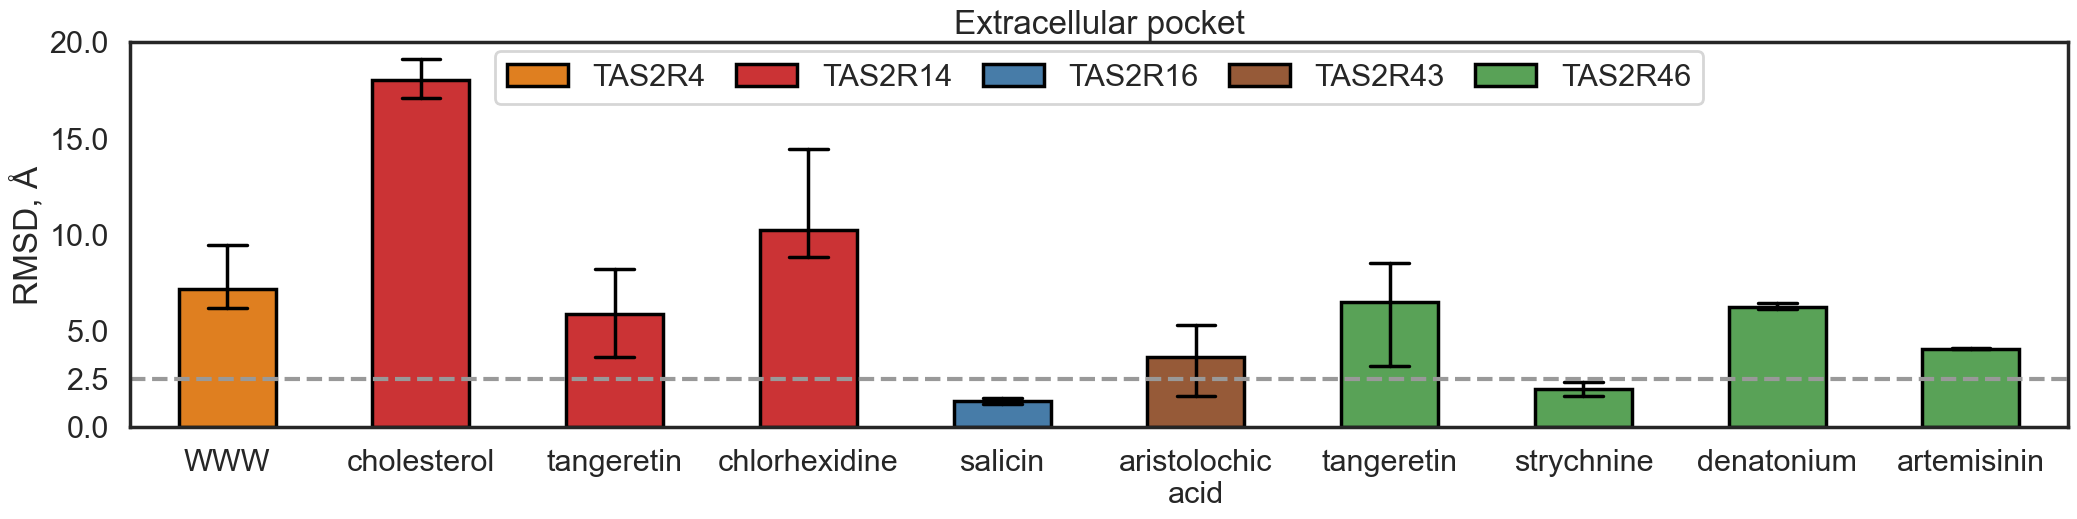

In [16]:
sns.set(rc={'figure.figsize':(25, 5)}, style='white', context='poster')

chart = sns.barplot(distr, x='complex', y='ligands rmsd', hue='receptor', hue_order=custom_palette.keys(), errorbar=('ci', 100), err_kws={'color': 'black', 'linewidth': 2.5}, capsize=0.2, linewidth=2.5, edgecolor='black',
                    width=0.5, palette=custom_palette)
labels = [item.get_text() for item in chart.get_xticklabels()]
new_labels = [label.split(' - ')[0] for label in labels]
new_labels = [label.replace(' ', '\n') if ' ' in label else label for label in new_labels]
chart.set_xticklabels(new_labels)
chart.set(ylabel='RMSD, Å', xlabel='', ylim=(0, 20), yticks=np.append(np.arange(0, 21, 5), 2.5), title='Extracellular pocket')
chart.axhline(2.5, color=palette[-1], linestyle='--')
sns.move_legend(chart, 'lower center', bbox_to_anchor=(0.5, 0.8), ncol=5, title='', columnspacing=1.0)
chart.figure.savefig('../figures/main/Figure 1A Extracellular pocket.png', dpi=300, bbox_inches='tight')
chart

### Inreacellular pocket

In [17]:
both_site_complexes = ['compound 28.1 - TAS2R14', 'flufenamic acid - TAS2R14', 'aristolochic acid - TAS2R14']
distr = ligands_distance_distribution_df[ligands_distance_distribution_df['complex'].isin(both_site_complexes)].reset_index(drop=True)
binding_site_order = ['extracellular', 'intracellular']
distr['binding site'] = pd.Categorical(distr['binding site'], categories=binding_site_order, ordered=True)
receptors_order = ['TAS2R14']
distr['receptor'] = pd.Categorical(distr['receptor'], categories=receptors_order, ordered=True)

/tmp/ipykernel_3812860/2644779467.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(new_labels)


<Axes: title={'center': 'Intracellular pocket'}, ylabel='RMSD, Å'>

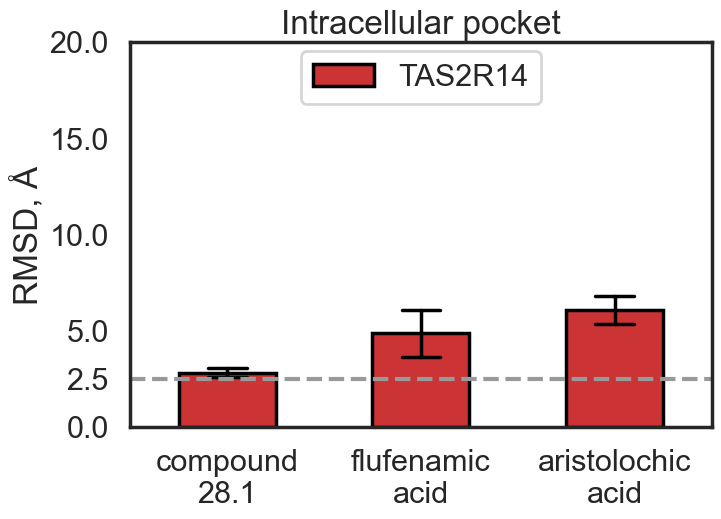

In [18]:
sns.set(rc={'figure.figsize':(7.5, 5)}, style='white', context='poster')

chart = sns.barplot(distr, x='complex', y='ligands rmsd', hue='receptor', errorbar=('ci', 100), err_kws={'color': 'black', 'linewidth': 2.5}, capsize=0.2, linewidth=2.5, edgecolor='black',
                    width=0.5, palette=custom_palette)
labels = [item.get_text() for item in chart.get_xticklabels()]
new_labels = [label.split(' - ')[0] for label in labels]
new_labels = [label.replace(' ', '\n') if ' ' in label else label for label in new_labels]
chart.set_xticklabels(new_labels)
chart.set(ylabel='RMSD, Å', xlabel='', ylim=(0, 20), yticks=np.append(np.arange(0, 21, 5), 2.5))
chart.set_title('Intracellular pocket', y=1.0)
chart.axhline(2.5, color=palette[-1], linestyle='--')
sns.move_legend(chart, 'lower center', bbox_to_anchor=(0.5, 0.8), ncol=4, title='', columnspacing=1.0)
chart.figure.savefig('../figures/main/Figure 1A Intracellular pocket.png', dpi=300, bbox_inches='tight')
chart